In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from torus_clock.model import load_model, capture

/home/bigburrito/icai/xai/torus-clock/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = load_model()

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 4916.27it/s]


In [3]:
rng = np.random.default_rng(0)
n, T, H = 300, 512, 64
t = np.arange(T + H)
phi0 = rng.uniform(0, 2*np.pi, size=(n,1))
x = 10 + 3 * np.cos(2*np.pi*t/24 + phi0) + 0.5 * rng.normal(size=(n, T + H))
context = torch.tensor(x[:, :T], dtype=torch.float32)
acts, out = capture(model, context)
q = out.quantile_preds

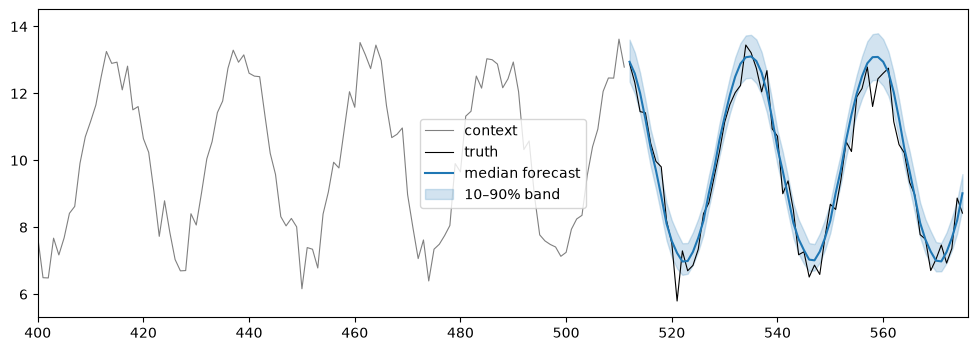

In [4]:
idx = 7

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[:T], x[idx, :T], color="gray", lw=0.8, label="context")
ax.plot(t[T:], x[idx, T:], color="black", lw=0.8, label="truth")
ax.plot(t[T:], q[idx, 4], color="C0", label="median forecast")
ax.fill_between(t[T:], q[idx, 0], q[idx, 8], color="C0", alpha=0.2, label="10–90% band")
ax.set_xlim(400, T + 64)
ax.legend()
plt.show()

In [5]:
patch_end = 16 * np.arange(32) + 15
phase = np.mod(2*np.pi*patch_end/24 + phi0, 2*np.pi)
y = phase.reshape(-1)

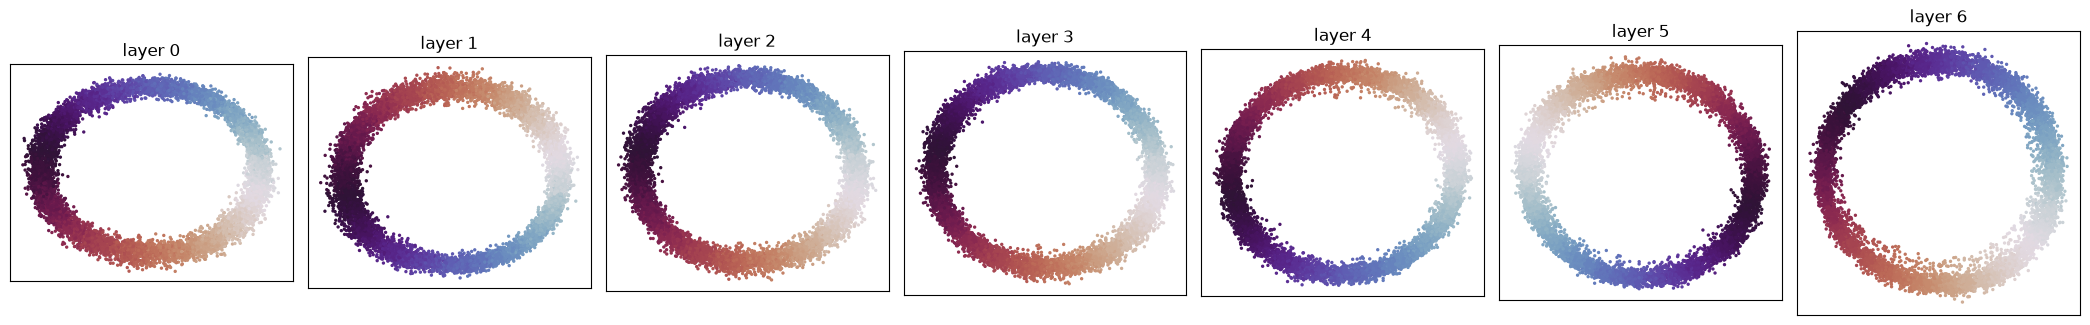

In [6]:
fig, axes = plt.subplots(1, 7, figsize=(21, 3.2))
for ax, (name, a) in zip(axes, acts.items()):
    X = a[:, :32].reshape(-1, 512)
    P = PCA(n_components=2).fit_transform(X)
    ax.scatter(P[:, 0], P[:, 1], c=y, cmap="twilight", s=2)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()